# KAN on a known-truth kinetics benchmark

The two chemistry notebooks ask whether a KAN's response curves can be read as chemistry. On real
data the truth is unknown, so this notebook builds a dataset from four textbook relationships with
literature constants and checks what the same pipeline recovers.

## The generating equations

A rate constant for a substituted aryl substrate reacting with a phosphine-ligated catalyst at
temperature $T$:

$$\log_{10} k = \log_{10} k_0 + \rho\,\sigma_p
\;-\;\frac{\Delta H^\ddagger}{2.303\,R}\left(\frac{1}{T}-\frac{1}{298.15}\right)
\;-\;\Delta\,\mathrm{sigmoid}\!\left(\frac{\%V_\mathrm{bur}(\min)-32}{w}\right)
\;-\;a\,(\Delta E_\mathrm{bind}-\Delta E_\mathrm{opt})^2 + \varepsilon$$

| Term | Law | Constants | Shape the pipeline should find |
|---|---|---|---|
| $\rho\,\sigma_p$ | Hammett | $\rho = 1.5$; $\sigma_p$ of 12 common substituents (NO$_2$ 0.78 to NMe$_2$ -0.83) | Linear |
| $-\Delta H^\ddagger/(2.303\,R)\,(1/T - 1/298.15)$ | Eyring/Arrhenius | $\Delta H^\ddagger = 15$ kcal/mol, $T$ from 288 to 368 K | Monotone, concave in $T$ |
| $-\Delta\,\mathrm{sigmoid}((\%V_\mathrm{bur}(\min)-32)/w)$ | Ligation-state cliff (Science 2021) | $\Delta = 1.5$ log units, $w = 1$ % | Step down near 32 % |
| $-a\,(\Delta E_\mathrm{bind}-\Delta E_\mathrm{opt})^2$ | Sabatier volcano | $a = 0.01$, $\Delta E_\mathrm{opt} = -15$ kcal/mol | Inverted U with the top at -15 |
| `noise_descriptor` | none | standard normal, unrelated to $k$ | Constant |

The noise $\varepsilon$ is normal with sd 0.15 log units. A second target replaces the Hammett
term with a mechanism break (different $\rho$ on each side of $\sigma = 0$, the classic
V-shaped Hammett plot); section 5 tests it separately.

## What this notebook does

Every dataset notebook in this series runs the same pipeline from `pycse.sklearn.kan_interpret`,
so the results are comparable across chemistries:

1. **Models on identical folds.** A linear baseline, random forest, gradient boosting and a KAN
   scored by 5x3 repeated cross-validation with the scaler refit inside each fold, and a paired
   Wilcoxon test of the KAN against the best other model.
2. **Single-descriptor thresholds.** Class-balanced stumps scored by balanced accuracy, with the
   majority baseline, so a "rule" that only predicts the majority class scores 0.5.
3. **Response curves that survive refitting.** Near-duplicate descriptors are pruned first, so
   an effect is not split between interchangeable columns. Each top descriptor then gets an
   accumulated local effect curve in its own units, with the linear baseline and the envelope
   of five refits, and the location of any step or window edge. A shape that changes from
   fold to fold is not a finding.
4. **A check against the known chemistry.** What the source paper established, or (for the
   synthetic benchmark) the generating equations, overlaid on what the pipeline recovered.

No emoji, no claims from a single fit.


In [1]:
import os

os.environ["JAX_PLATFORM_NAME"] = "cpu"
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, accuracy_score

from pycse.sklearn.kan import KAN
from pycse.sklearn.kan_interpret import (
    accumulated_local_effects,
    accumulated_local_effects_cv,
    classify_shape,
    cv_compare,
    partial_effects,
    partial_effects_cv,
    plot_fold_scores,
    plot_partial_effect,
    prune_collinear,
    sensitivity,
    threshold_rules,
    transitions,
)
from pycse.sklearn._plotstyle import (
    INK,
    INK_2,
    MUTED,
    BASELINE,
    SURFACE,
    SERIES,
    PX,
    style_axes,
    finish_axes,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Record the environment: KAN fits move slightly between jax/XLA builds.
import importlib.metadata as _md

print(
    "Versions:",
    ", ".join(
        f"{p} {_md.version(p)}" for p in ("pycse", "jax", "optax", "numpy", "scikit-learn", "scipy")
    ),
)


Versions: pycse 2.13.0, jax 0.12.0.1, optax 0.2.8, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1


## 1. Build the dataset

600 reactions: substituents drawn from the 12-entry Hammett table, the other descriptors uniform
over their ranges. The truth terms are kept as functions so they can be overlaid on the recovered
curves later.


In [2]:
R_CAL = 1.987e-3  # kcal/(mol K)
SIGMA_P = {
    "NO2": 0.78, "CN": 0.66, "CF3": 0.54, "CO2Me": 0.45, "Cl": 0.23, "Br": 0.23,
    "F": 0.06, "H": 0.00, "Me": -0.17, "tBu": -0.20, "OMe": -0.27, "NMe2": -0.83,
}  # fmt: skip
RHO, DH_ACT, CLIFF_DROP, CLIFF_W, VOLCANO_A, E_OPT = 1.5, 15.0, 1.5, 1.0, 0.01, -15.0
LOG_K0, NOISE_SD, N = -3.0, 0.15, 600


def term_hammett(s):
    return RHO * s


def term_eyring(T):
    return -DH_ACT / (2.303 * R_CAL) * (1.0 / T - 1.0 / 298.15)


def term_cliff(v):
    return -CLIFF_DROP / (1.0 + np.exp(-(v - 32.0) / CLIFF_W))


def term_volcano(e):
    return -VOLCANO_A * (e - E_OPT) ** 2


def term_none(z):
    return np.zeros_like(np.asarray(z, dtype=float))


TRUTH = {
    "sigma_p": term_hammett,
    "T_K": term_eyring,
    "pct_Vbur_min": term_cliff,
    "dE_bind": term_volcano,
    "noise_descriptor": term_none,
}

rng = np.random.default_rng(2021)
subst = rng.choice(list(SIGMA_P), size=N)
df = pd.DataFrame(
    {
        "substituent": subst,
        "sigma_p": [SIGMA_P[s] for s in subst],
        "T_K": rng.uniform(288.0, 368.0, N),
        "pct_Vbur_min": rng.uniform(22.0, 50.0, N),
        "dE_bind": rng.uniform(-30.0, 0.0, N),
        "noise_descriptor": rng.normal(size=N),
    }
)
df["log10_k"] = LOG_K0 + sum(TRUTH[f](df[f].to_numpy()) for f in TRUTH) + rng.normal(0, NOISE_SD, N)

X_df = df[list(TRUTH)]
y = df["log10_k"].to_numpy()
TASK = "regression"
Y_LABEL = "log10 k"
COMPONENT = {"sigma_p": "substrate", "T_K": "conditions", "pct_Vbur_min": "ligand", "dE_bind": "catalyst", "noise_descriptor": "none"}
SUCCESS = (y > np.median(y)).astype(int)
SUCCESS_RULE = "log10 k above the median"
display(df.head())

# Descriptors a published hypothesis names; kept first when duplicates are pruned.
HYPOTHESIS = ['sigma_p', 'T_K', 'pct_Vbur_min', 'dE_bind']
HYPOTHESIS_CONTEXT = []


,substituent,sigma_p,T_K,pct_Vbur_min,dE_bind,noise_descriptor,log10_k
0,tBu,-0.20,327.615847,30.059084,-19.834695,1.072492,-3.091883
1,tBu,-0.20,351.171422,30.250365,-23.624701,0.732806,-2.552929
2,Br,0.23,311.291715,49.162883,-17.330664,-0.242474,-3.654478
3,NMe2,-0.83,300.464851,34.633344,-23.203925,-0.559901,-6.348026
4,H,0.00,316.280646,41.681293,-5.843115,0.396553,-4.913302


600 reactions, 5 descriptors. Target: log10 k (regression).
Success for the threshold rules: log10 k above the median (50% of reactions).


,Component,Distinct,Min,Max
sigma_p,substrate,11,-0.830,0.780
T_K,conditions,600,288.069,367.919
pct_Vbur_min,ligand,600,22.003,49.949
dE_bind,catalyst,600,-29.992,-0.191
noise_descriptor,none,600,-4.367,2.652


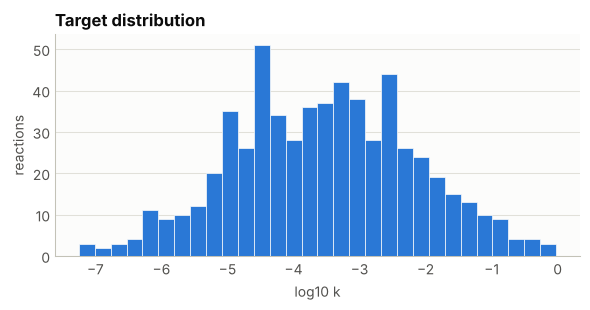

In [3]:
feature_names = list(X_df.columns)
X = X_df.to_numpy(dtype=float)
y = np.asarray(y, dtype=float)
SUCCESS = np.asarray(SUCCESS, dtype=int)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}

desc = pd.DataFrame(
    {
        "Component": [COMPONENT[f] for f in feature_names],
        "Distinct": X_df.nunique().values,
        "Min": X_df.min().values,
        "Max": X_df.max().values,
    },
    index=feature_names,
)
print(f"{len(X)} reactions, {n_features} descriptors. Target: {Y_LABEL} ({TASK}).")
print(f"Success for the threshold rules: {SUCCESS_RULE} ({SUCCESS.mean():.0%} of reactions).")
display(desc.round(3))

fig, ax = plt.subplots(figsize=(6, 3.2))
style_axes(ax)
if TASK == "regression":
    ax.hist(y, bins=30, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    finish_axes(ax, "Target distribution", Y_LABEL, "reactions")
else:
    vals, counts = np.unique(y, return_counts=True)
    ax.bar(vals, counts, width=0.6, color=[MUTED, SERIES[0]], linewidth=0)
    ax.set_xticks(vals)
    ax.set_xticklabels([f"{int(v)} ({c})" for v, c in zip(vals, counts)])
    finish_axes(ax, "Class balance", Y_LABEL, "reactions")
plt.tight_layout()
plt.show()


### 1.1 One descriptor per group of near-duplicates

Two descriptors that are near copies of each other (absolute correlation above 0.85) split one
effect between them arbitrarily, so a curve for either one is not identifiable. The pipeline
keeps the first descriptor of each group, the one the source paper names when there is one,
and drops the rest for every model.


In [4]:
PRUNE_R = 0.85
kept, dropped = prune_collinear(X, feature_names, PRUNE_R, keep_first=HYPOTHESIS)
for name, (partner, r) in dropped.items():
    print(f"dropped {name}: |r| = {r:.2f} with {partner}, which stays")
if not dropped:
    print(f"No pair of descriptors correlates above {PRUNE_R}; all {n_features} stay.")
X_df = X_df[kept]
feature_names = kept
X = X_df.to_numpy(dtype=float)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}
print(f"{n_features} descriptors go into every model.")


No pair of descriptors correlates above 0.85; all 5 stay.
5 descriptors go into every model.


## 2. Models on identical folds

The four models see exactly the same 15 folds (5 splits x 3 repeats, scaler refit per fold).
The paired comparison asks a narrow question: on the same held-out reactions, is the KAN better
than the best of the other models, and how often?

The KAN carries light L1 and entropy penalties on its spline coefficients, at the same strength
(1e-3) in every notebook of the series. That strength was chosen once, on three of the datasets,
as the largest that cost no cross-validated accuracy: the benchmark stayed at R² 0.984, and the
deoxyfluorination and ligand sets improved. Ten times more cost accuracy on both regression sets.


Model                  r2               other
MLR                    0.673 ± 0.036   0.647 ± 0.027 (mae)
Random Forest          0.912 ± 0.016   0.317 ± 0.024 (mae)
Gradient Boosting      0.963 ± 0.006   0.209 ± 0.014 (mae)
KAN                    0.983 ± 0.004   0.142 ± 0.015 (mae)
KAN vs Gradient Boosting, paired over 15 folds: Δr2 = +0.0201 ± 0.0057, KAN better in 15/15, Wilcoxon p = 6.1e-05
(118 s)


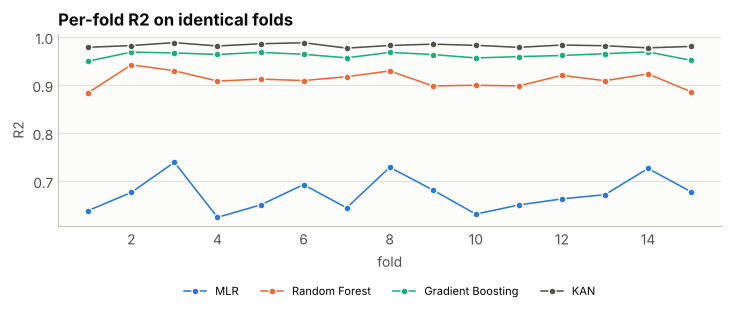

In [5]:
# One hidden layer; width 8 and 5 knots on datasets of 1000 reactions or more,
# 4 and 3 below that, so the spline count stays in proportion to the data.
WIDE = len(X) >= 1000
KAN_LAYERS = (n_features, 8 if WIDE else 4, 1)
KAN_GRID = 5 if WIDE else 3
KAN_REG = 1e-3  # L1 and entropy penalty on the spline coefficients
KAN_MAXITER = 300
CV_SPLITS, CV_REPEATS, CV_SEED = 5, 3, 42


def make_kan():
    return KAN(
        layers=KAN_LAYERS, grid_size=KAN_GRID, spline_order=3, l1_spline=KAN_REG, entropy_reg=KAN_REG
    )


def make_models():
    """Fresh models; the ensembles use the settings of the first two chemistry notebooks."""
    if TASK == "regression":
        return {
            "MLR": LinearRegression(),
            "Random Forest": RandomForestRegressor(
                n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
                random_state=42, n_jobs=-1,
            ),  # fmt: skip
            "Gradient Boosting": GradientBoostingRegressor(
                n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
                min_samples_leaf=3, subsample=0.8, random_state=42,
            ),  # fmt: skip
            "KAN": make_kan(),
        }
    return {
        "Logistic": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
            random_state=42, n_jobs=-1,
        ),  # fmt: skip
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
            min_samples_leaf=3, subsample=0.8, random_state=42,
        ),  # fmt: skip
        "KAN": make_kan(),
    }


BASELINE_NAME = "MLR" if TASK == "regression" else "Logistic"

t0 = time.time()
cv_result = cv_compare(
    make_models(),
    X,
    y,
    task=TASK,
    n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS,
    random_state=CV_SEED,
    fit_kwargs={"KAN": {"maxiter": KAN_MAXITER}},
    verbose=False,
)
print(cv_result)
print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_fold_scores(ax, cv_result)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()


Held-out split: 480 train / 120 test


,Test R2,Test MAE
Model,,
MLR,0.639,0.614
Random Forest,0.887,0.354
Gradient Boosting,0.953,0.226
KAN,0.979,0.147


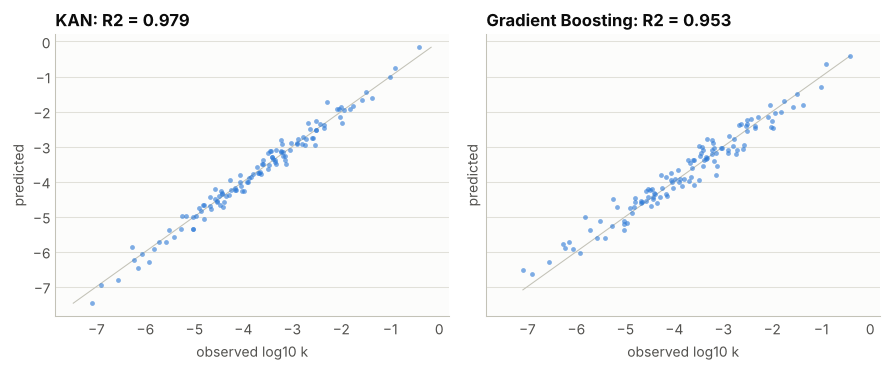

In [6]:
# One held-out split for the models the rest of the notebook interprets.
strat = y.astype(int) if TASK == "classification" else None
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42, stratify=strat)
scaler = StandardScaler().fit(X[idx_tr])
X_tr, X_te = scaler.transform(X[idx_tr]), scaler.transform(X[idx_te])
y_tr, y_te = y[idx_tr], y[idx_te]

fitted, rows = {}, []
for name, model in make_models().items():
    if name == "KAN":
        model.fit(X_tr, y_tr, maxiter=KAN_MAXITER)
    else:
        model.fit(X_tr, y_tr.astype(int) if TASK == "classification" else y_tr)
    fitted[name] = model
    if TASK == "regression":
        p = model.predict(X_te)
        rows.append({"Model": name, "Test R2": r2_score(y_te, p), "Test MAE": mean_absolute_error(y_te, p)})
    else:
        p = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else np.clip(model.predict(X_te), 0, 1)
        rows.append({"Model": name, "Test AUC": roc_auc_score(y_te, p), "Test accuracy": accuracy_score(y_te, (p > 0.5).astype(int))})
kan, baseline = fitted["KAN"], fitted[BASELINE_NAME]


def model_means(labels, model=None):
    """Observed and predicted mean target per group, over the training reactions.

    A partial effect fixes the other descriptors at their mean, which is not a real
    compound; to compare a model with observed group means, average its predictions
    over the reactions that were actually run.
    """
    model = model or kan
    pred = np.ravel(model.predict(X_tr))
    lab = np.asarray(labels)[idx_tr]
    return (
        pd.DataFrame({"label": lab, "observed": y[idx_tr], "predicted": pred})
        .groupby("label")
        .agg(observed=("observed", "mean"), predicted=("predicted", "mean"), n=("observed", "size"))
    )
headline = pd.DataFrame(rows).set_index("Model")
print(f"Held-out split: {len(idx_tr)} train / {len(idx_te)} test")
display(headline.round(3))

# The KAN against the best other model on the held-out reactions
metric = "Test R2" if TASK == "regression" else "Test AUC"
best_other = headline.drop("KAN")[metric].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for ax, name in zip(axes, ["KAN", best_other]):
    style_axes(ax)
    m = fitted[name]
    if TASK == "regression":
        p = m.predict(X_te)
        lim = [min(y_te.min(), p.min()), max(y_te.max(), p.max())]
        ax.plot(lim, lim, color=BASELINE, linewidth=PX, zorder=1)
        ax.scatter(y_te, p, s=12, color=SERIES[0], alpha=0.6, linewidths=0, zorder=2)
        finish_axes(ax, f"{name}: R2 = {headline.loc[name, metric]:.3f}", f"observed {Y_LABEL}", "predicted")
    else:
        p = m.predict_proba(X_te)[:, 1] if hasattr(m, "predict_proba") else np.clip(m.predict(X_te), 0, 1)
        bins = np.linspace(0, 1, 21)
        ax.hist(p[y_te == 0], bins=bins, color=MUTED, alpha=0.7, label="observed 0", linewidth=0)
        ax.hist(p[y_te == 1], bins=bins, color=SERIES[0], alpha=0.7, label="observed 1", linewidth=0)
        ax.legend(frameon=False, fontsize=8)
        finish_axes(ax, f"{name}: AUC = {headline.loc[name, metric]:.3f}", "predicted probability", "reactions")
plt.tight_layout()
plt.show()


## 3. Single-descriptor thresholds

The Doyle and Sigman groups look for reactivity cliffs with one cut on one descriptor. The same
search here: a depth-1 tree with balanced class weights on each descriptor, scored on the held-out
reactions by balanced accuracy. A descriptor with no information scores 0.5 whatever the class
balance.


Majority-class accuracy on the test reactions: 0.533
Balanced-accuracy baseline for guessing: 0.500


,Feature,Threshold,Balanced_Acc,Accuracy,Precision,Recall
0,T_K,323.146,0.729,0.725,0.677,0.786
1,sigma_p,0.145,0.682,0.683,0.661,0.661
2,pct_Vbur_min,32.649,0.650,0.658,0.674,0.518
3,dE_bind,-24.958,0.593,0.575,0.527,0.857
4,noise_descriptor,-1.509,0.519,0.492,0.477,0.929


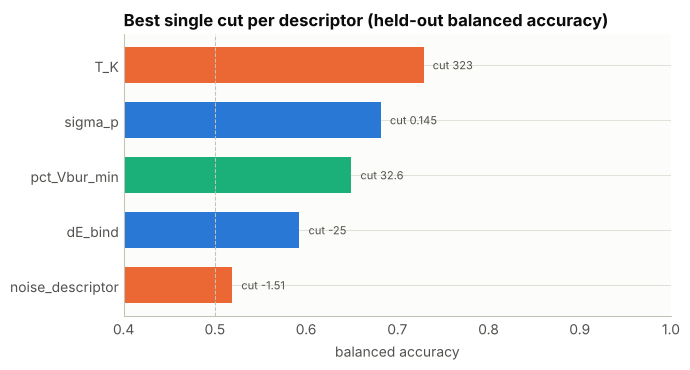

In [7]:
rules = threshold_rules(X[idx_tr], SUCCESS[idx_tr], feature_names, X[idx_te], SUCCESS[idx_te])
print(f"Majority-class accuracy on the test reactions: {rules.attrs['majority_accuracy']:.3f}")
print("Balanced-accuracy baseline for guessing: 0.500")
display(rules.head(10).round(3))

top = rules.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
style_axes(ax)
ax.barh(top.Feature, top.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top.Feature], height=0.65, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
for yk, (f, b, t) in enumerate(zip(top.Feature, top.Balanced_Acc, top.Threshold)):
    ax.text(b + 0.01, yk, f"cut {t:.3g}", va="center", fontsize=8, color=INK_2)
finish_axes(ax, "Best single cut per descriptor (held-out balanced accuracy)", "balanced accuracy", "")
plt.tight_layout()
plt.show()


## 4. Response curves, read as accumulated local effects

Sensitivity ranks the descriptors by how much the KAN prediction moves per standardized unit,
averaged over the training reactions. The top descriptors, among those with at least five
distinct values, then get a response curve in their own units.

The curve is an accumulated local effect rather than a partial effect. A partial effect holds
every other descriptor at its mean, which describes a compound that does not exist, and when
descriptors are correlated it asks the model about combinations it never saw. The accumulated
local effect moves a descriptor only within the reactions that already sit near each value and
adds up the local changes (Apley and Zhu, *J. R. Stat. Soc. B* 2020). The cell after the curves
puts the two readings side by side.

Each curve comes with the linear baseline read the same way, the envelope of five refits on
disjoint folds, and the observed values along the bottom. The curve is centred on the model's
mean prediction and adds up local changes, so at a sparsely sampled end it can leave the range of
the target: a probability curve that dips below zero there says "few reactions, still falling",
not that a probability is negative.


,Feature,Component,Sensitivity
0,dE_bind,catalyst,1.3053
1,T_K,conditions,0.7030
2,pct_Vbur_min,ligand,0.6279
3,sigma_p,substrate,0.6065
4,noise_descriptor,none,0.0324


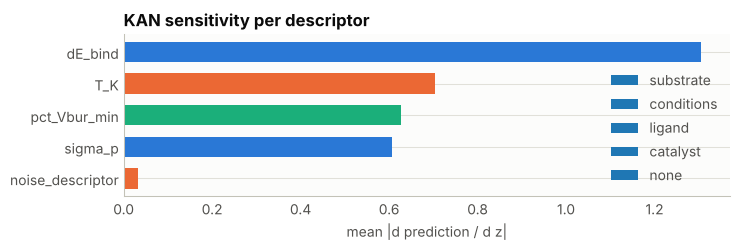

5 descriptors with at least 5 distinct values; 0 with fewer, shown as levels below.


curves and fold envelopes: 82 s


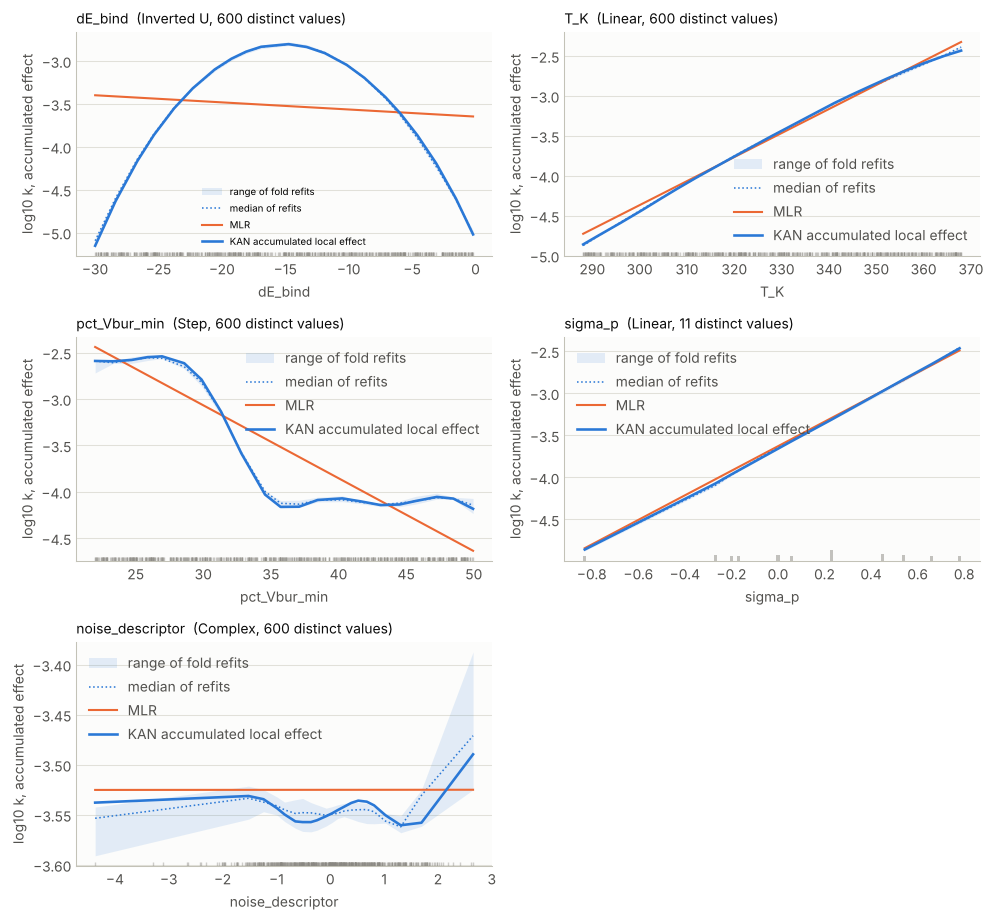

In [8]:
sens = sensitivity(kan, X_tr, task=TASK)
sens_df = pd.DataFrame(
    {"Feature": feature_names, "Component": [COMPONENT[f] for f in feature_names], "Sensitivity": sens}
).sort_values("Sensitivity", ascending=False).reset_index(drop=True)
display(sens_df.round(4))

fig, ax = plt.subplots(figsize=(7.5, 0.28 * n_features + 1.2))
style_axes(ax)
sd = sens_df.iloc[::-1]
ax.barh(sd.Feature, sd.Sensitivity, color=[COMP_COLOR[c] for c in sd.Component], height=0.65, linewidth=0)
for c in COMPONENTS:
    ax.barh([], [], color=COMP_COLOR[c], label=c)
ax.legend(frameon=False, fontsize=8, loc="lower right")
finish_axes(ax, "KAN sensitivity per descriptor", "mean |d prediction / d z|", "")
plt.tight_layout()
plt.show()

# A response curve needs values to interpolate between. Descriptors with fewer
# than five distinct values are handled as levels in a later cell instead.
MIN_LEVELS = 5
rich = [f for f in feature_names if X_df[f].nunique() >= MIN_LEVELS]
few = [f for f in feature_names if f not in rich]
top_features = sens_df[sens_df.Feature.isin(rich)].Feature.head(8).tolist()
TOP_K = len(top_features)
print(f"{len(rich)} descriptors with at least {MIN_LEVELS} distinct values; {len(few)} with fewer, shown as levels below.")
SHAPE_SCALE = y.std() if TASK == "regression" else 1.0
# An accumulated local effect is centred on the mean prediction and adds up local changes, so
# at a sparsely sampled end it can leave the range of the target (below 0 for a probability).
ALE_LABEL = f"{Y_LABEL}, accumulated effect"

t0 = time.time()
effects = accumulated_local_effects(
    kan, X, feature_names, top_features, scaler=scaler, task=TASK,
    extra_models={BASELINE_NAME: baseline},
)  # fmt: skip
effects = accumulated_local_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=effects, verbose=False,
)  # fmt: skip
print(f"curves and fold envelopes: {time.time() - t0:.0f} s")

ncol = 2
nrow = int(np.ceil(TOP_K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 3.1 * nrow))
for ax, f in zip(np.ravel(axes), top_features):
    plot_partial_effect(ax, effects[f], ylabel=ALE_LABEL)
    label = effects[f].shape(scale=SHAPE_SCALE)[0]
    ax.set_title(f"{f}  ({label}, {effects[f].n_unique} distinct values)", loc="left", fontsize=10)
for ax in np.ravel(axes)[TOP_K:]:
    ax.axis("off")
np.ravel(axes)[0].legend(frameon=False, fontsize=7, loc="best")
plt.tight_layout()
plt.show()


,Feature,Partial effect,Refits agreeing (PE),Accumulated local effect,Refits agreeing (ALE)
0,dE_bind,Inverted U,1.0,Inverted U,1.0
1,T_K,Linear,1.0,Linear,1.0
2,pct_Vbur_min,Step,1.0,Step,1.0
3,sigma_p,Linear,1.0,Linear,1.0
4,noise_descriptor,Gap,0.2,Complex,0.6


Mean fraction of refits agreeing on the shape: partial effect 0.84, accumulated local effect 0.92


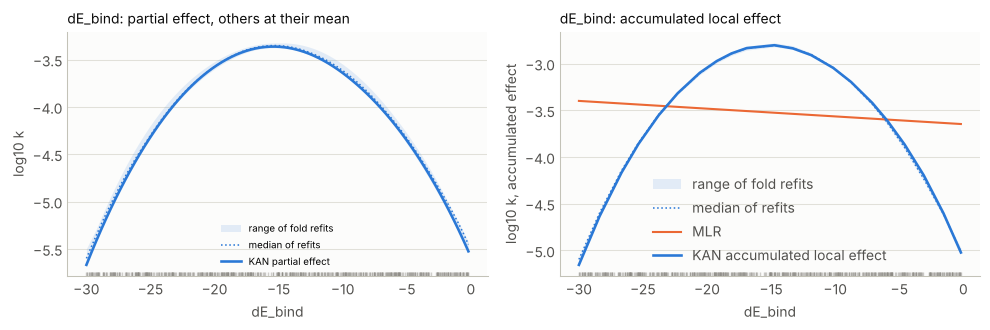

In [9]:
# The same KAN read both ways, with the same five refits behind each envelope.
pd_effects = partial_effects(kan, X, feature_names, top_features, scaler=scaler, task=TASK)
pd_effects = partial_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=pd_effects, verbose=False,
)  # fmt: skip


def agreement(pe):
    """The full fit's shape label, and the fraction of refits that share it."""
    label = pe.shape(scale=SHAPE_SCALE)[0]
    folds = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
    return label, float(np.mean([lab == label for lab in folds]))


rows = []
for f in top_features:
    s_pe, a_pe = agreement(pd_effects[f])
    s_ale, a_ale = agreement(effects[f])
    rows.append(
        {
            "Feature": f,
            "Partial effect": s_pe,
            "Refits agreeing (PE)": a_pe,
            "Accumulated local effect": s_ale,
            "Refits agreeing (ALE)": a_ale,
        }
    )
reading_cmp = pd.DataFrame(rows)
display(reading_cmp.round(2))
print(
    f"Mean fraction of refits agreeing on the shape: partial effect "
    f"{reading_cmp['Refits agreeing (PE)'].mean():.2f}, accumulated local effect "
    f"{reading_cmp['Refits agreeing (ALE)'].mean():.2f}"
)

f0 = top_features[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
plot_partial_effect(axes[0], pd_effects[f0], ylabel=Y_LABEL)
plot_partial_effect(axes[1], effects[f0], ylabel=ALE_LABEL)
for ax, how in zip(axes, ["partial effect, others at their mean", "accumulated local effect"]):
    ax.set_title(f"{f0}: {how}", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()


In [10]:
# Descriptors with four or fewer levels. A response curve needs a grid; these get a
# table instead: the observed mean per level and the model's mean prediction over the
# same reactions (not at an averaged molecule, which is not a real compound).
if few:
    pred_tr = np.ravel(kan.predict(X_tr))
    rows = []
    for f in few:
        j = feature_names.index(f)
        for lvl in np.unique(X[:, j]):
            at = X[idx_tr, j] == lvl
            rows.append(
                {
                    "Feature": f,
                    "Component": COMPONENT[f],
                    "Level": lvl,
                    "Reactions": int((X[:, j] == lvl).sum()),
                    "Observed mean": float(y[X[:, j] == lvl].mean()),
                    "KAN mean prediction": float(pred_tr[at].mean()) if at.any() else np.nan,
                }
            )
    levels = pd.DataFrame(rows)
    display(levels.round(3))
    spread = levels.groupby("Feature")["Observed mean"].agg(lambda s: s.max() - s.min())
    print("Observed spread across the levels of each few-level descriptor:")
    print(spread.round(1).sort_values(ascending=False).to_string())
else:
    levels = pd.DataFrame()
    print("Every descriptor has at least five distinct values; nothing to show here.")


Every descriptor has at least five distinct values; nothing to show here.


In [11]:
# Shape of the full fit, whether the five refits agree on it, and where its edges are.
# A curve whose range is under 5 % of the target's spread is "Constant" whatever its wiggles.
EDGED = {"Step", "Window", "Gap", "Saturating"}


def edge_range(values):
    values = [v for v in values if v is not None]
    if not values:
        return ""
    return f"{min(values):.3g} to {max(values):.3g} ({len(values)} of 5)"


def stability_table(effects):
    rows = []
    for f, pe in effects.items():
        label, _ = pe.shape(scale=SHAPE_SCALE)
        fold_labels = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
        agree = float(np.mean([lab == label for lab in fold_labels]))
        width = float(np.mean(pe.hi - pe.lo) / (np.ptp(pe.median) + 1e-9))
        tr = transitions(pe.x_raw, pe.y)
        folds = [transitions(pe.x_raw, c) for c in pe.curves]
        edged = label in EDGED
        rows.append(
            {
                "Feature": f,
                "Component": COMPONENT[f],
                "Shape": label,
                "Nonlinearity": pe.nonlinearity(),
                "Fold agreement": agree,
                "Envelope / range": width,
                "Rise": tr["rise"] if edged else None,
                "Fall": tr["fall"] if edged else None,
                "Rise in refits": edge_range([t["rise"] for t in folds]) if edged else "",
                "Fall in refits": edge_range([t["fall"] for t in folds]) if edged else "",
                "Fold shapes": ", ".join(fold_labels),
            }
        )
    return pd.DataFrame(rows)


stab = stability_table(effects)
display(stab.round(3))
stable = stab[(stab["Fold agreement"] >= 0.8) & (stab["Envelope / range"] < 0.5)]
print("Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):")
for _, r in stable.iterrows():
    print(f"  {r.Feature}: {r.Shape}")
print("Shapes that do not:")
for _, r in stab.drop(stable.index).iterrows():
    print(f"  {r.Feature}: full fit {r.Shape}; refits {r['Fold shapes']}")


,Feature,Component,Shape,Nonlinearity,Fold agreement,Envelope / range,Rise,Fall,Rise in refits,Fall in refits,Fold shapes
0,dE_bind,catalyst,Inverted U,1.000,1.0,0.016,None,NaN,,,"Inverted U, Inverted U, Inverted U, Inverted U..."
1,T_K,conditions,Linear,0.066,1.0,0.008,None,NaN,,,"Linear, Linear, Linear, Linear, Linear"
2,pct_Vbur_min,ligand,Step,0.464,1.0,0.039,None,32.066,,32 to 32.1 (5 of 5),"Step, Step, Step, Step, Step"
3,sigma_p,substrate,Linear,0.023,1.0,0.010,None,NaN,,,"Linear, Linear, Linear, Linear, Linear"
4,noise_descriptor,none,Complex,0.984,0.6,0.309,None,NaN,,,"Constant, Complex, Constant, Complex, Complex"


Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):
  dE_bind: Inverted U
  T_K: Linear
  pct_Vbur_min: Step
  sigma_p: Linear
Shapes that do not:
  noise_descriptor: full fit Complex; refits Constant, Complex, Constant, Complex, Complex


## 4.1 The paper's descriptors on their own

A KAN given only the descriptors a hypothesis names, plus the context it needs (for example which
substrate pair was run), answers a narrower question than the full model: does that descriptor
carry a threshold or an optimum, and where. It is scored on the same 15 folds as the models
above, so the comparison with the full KAN is paired.


4 inputs: sigma_p, T_K, pct_Vbur_min, dE_bind
R2: hypothesis-only KAN 0.978 ± 0.005, full KAN 0.983 ± 0.004; better in 3/15 folds


,Feature,Shape,Nonlinearity,Fold agreement,Envelope / range,Rise,Fall,Rise in refits,Fall in refits,Fold shapes
0,sigma_p,Linear,0.017,1.0,0.015,None,NaN,,,"Linear, Linear, Linear, Linear, Linear"
1,T_K,Linear,0.073,1.0,0.008,None,NaN,,,"Linear, Linear, Linear, Linear, Linear"
2,pct_Vbur_min,Step,0.469,1.0,0.073,None,31.779,,31.7 to 32.5 (5 of 5),"Step, Step, Step, Step, Step"
3,dE_bind,Inverted U,1.000,1.0,0.018,None,NaN,,,"Inverted U, Inverted U, Inverted U, Inverted U..."


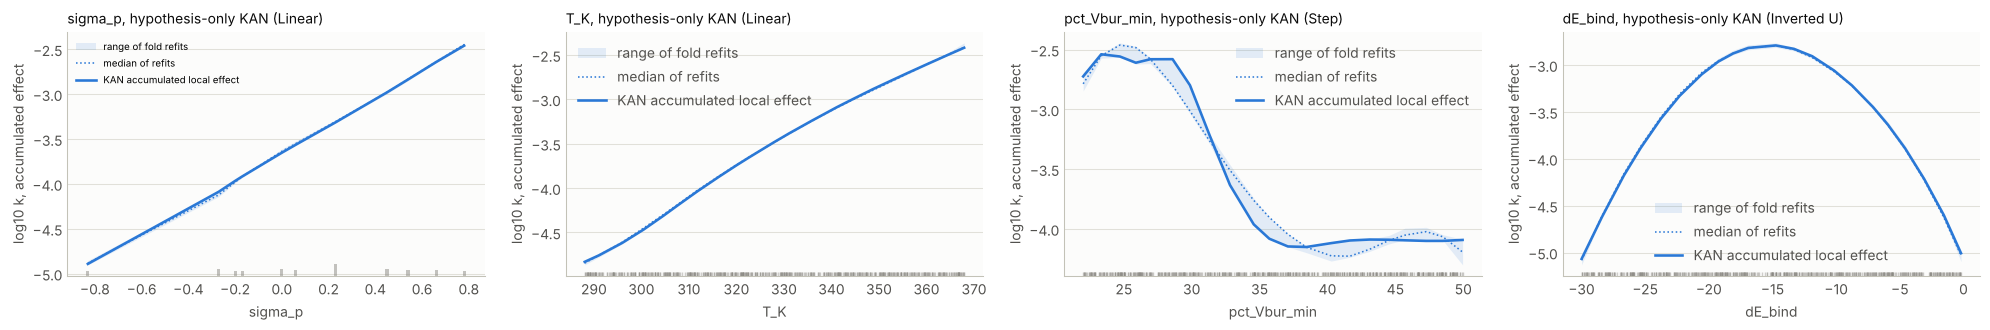

In [12]:
hyp_cols = [c for c in HYPOTHESIS + HYPOTHESIS_CONTEXT if c in feature_names]
Xh = X_df[hyp_cols].to_numpy(dtype=float)


def make_small_kan():
    return KAN(
        layers=(len(hyp_cols), 2, 1), grid_size=KAN_GRID, spline_order=3,
        l1_spline=KAN_REG, entropy_reg=KAN_REG,
    )  # fmt: skip


hyp_res = cv_compare(
    {"KAN, hypothesis only": make_small_kan()}, Xh, y, task=TASK, n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS, random_state=CV_SEED,
    fit_kwargs={"KAN, hypothesis only": {"maxiter": KAN_MAXITER}}, verbose=False,
)  # fmt: skip
m = cv_result.metric
small = hyp_res.folds.sort_values("fold")[m].to_numpy()
full = cv_result.folds[cv_result.folds.model == "KAN"].sort_values("fold")[m].to_numpy()
d = small - full
print(f"{len(hyp_cols)} inputs: {', '.join(hyp_cols)}")
print(
    f"{m.upper()}: hypothesis-only KAN {small.mean():.3f} ± {small.std(ddof=1):.3f}, "
    f"full KAN {full.mean():.3f} ± {full.std(ddof=1):.3f}; better in {(d > 0).sum()}/{len(d)} folds"
)

hyp_scaler = StandardScaler().fit(Xh[idx_tr])
small_kan = make_small_kan().fit(hyp_scaler.transform(Xh[idx_tr]), y[idx_tr], maxiter=KAN_MAXITER)
hyp_effects = accumulated_local_effects(small_kan, Xh, hyp_cols, HYPOTHESIS, scaler=hyp_scaler, task=TASK)
hyp_effects = accumulated_local_effects_cv(
    make_small_kan, Xh, y, hyp_cols, HYPOTHESIS, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=hyp_effects, verbose=False,
)  # fmt: skip
hyp_stab = stability_table(hyp_effects)
display(hyp_stab.drop(columns=["Component"]).round(3))

fig, axes = plt.subplots(1, len(HYPOTHESIS), figsize=(5 * len(HYPOTHESIS), 3.4), squeeze=False)
for ax, f in zip(axes[0], HYPOTHESIS):
    plot_partial_effect(ax, hyp_effects[f], ylabel=ALE_LABEL)
    ax.set_title(f"{f}, hypothesis-only KAN ({hyp_effects[f].shape(scale=SHAPE_SCALE)[0]})", loc="left", fontsize=10)
axes[0][0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()


## 5. Check against the generating equations

Each recovered curve is compared with the term that generated it. Accumulated local effects are
centred on the model's mean prediction, so each truth curve is centred the same way: the term,
minus its average over the reactions, plus that mean prediction. The linear baseline is read the
same way. The last cell swaps in a mechanism-break target and asks the same question of the
Hammett curve alone.


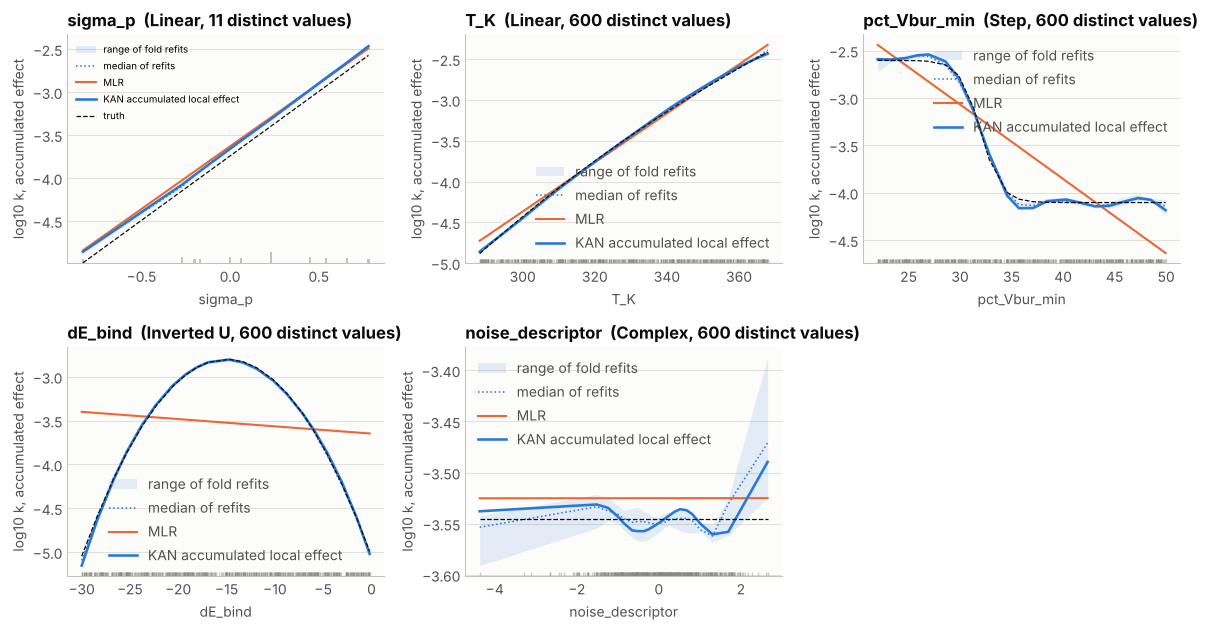

,Feature,True shape,KAN shape,RMSE KAN,RMSE linear
0,sigma_p,Linear,Linear,0.092,0.109
1,T_K,Monotone (concave),Linear,0.017,0.059
2,pct_Vbur_min,Step,Step,0.046,0.314
3,dE_bind,Inverted U,Inverted U,0.028,0.729
4,noise_descriptor,Constant,Complex,0.015,0.020


Noise sd in the data: 0.15; a curve within about that of the truth is as good as the data allow.
Cliff generated at 32.0 %. Best single cut: 32.65 %. KAN falling edge: 32.07 %.
Falling edge in the five refits: [32.06, 32.02, 31.95, 32.11, 32.12]


In [13]:
# Each recovered curve against the term that generated it. An accumulated local effect is
# centred on the model's mean prediction, so the truth is centred the same way: the
# generating term, minus its average over the reactions, plus that mean prediction.
TRUE_SHAPE = {
    "sigma_p": "Linear", "T_K": "Monotone (concave)", "pct_Vbur_min": "Step",
    "dE_bind": "Inverted U", "noise_descriptor": "Constant",
}  # fmt: skip
level = float(np.mean(np.ravel(kan.predict(scaler.transform(X)))))


def truth_on(pe, f):
    return TRUTH[f](pe.x_raw) - np.mean(TRUTH[f](X[:, feature_names.index(f)])) + level


fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
err_rows = []
for ax, f in zip(np.ravel(axes), feature_names):
    if f in effects:
        pe = effects[f]
    else:
        pe = accumulated_local_effects(
            kan, X, feature_names, [f], scaler=scaler, task=TASK, extra_models={BASELINE_NAME: baseline}
        )[f]
    truth = truth_on(pe, f)
    plot_partial_effect(ax, pe, ylabel=ALE_LABEL)
    ax.plot(pe.x_raw, truth, color=INK, linewidth=1.2 * PX, linestyle="--", label="truth", zorder=5)
    err_rows.append(
        {
            "Feature": f,
            "True shape": TRUE_SHAPE[f],
            "KAN shape": pe.shape(scale=SHAPE_SCALE)[0],
            "RMSE KAN": np.sqrt(np.mean((pe.y - truth) ** 2)),
            "RMSE linear": np.sqrt(np.mean((pe.extra[BASELINE_NAME] - truth) ** 2)),
        }
    )
np.ravel(axes)[0].legend(frameon=False, fontsize=7)
np.ravel(axes)[-1].axis("off")
plt.tight_layout()
plt.show()
check = pd.DataFrame(err_rows)
display(check.round(3))
print(f"Noise sd in the data: {NOISE_SD}; a curve within about that of the truth is as good as the data allow.")

# The cliff: where did the single cut, the KAN and its refits put it?
pe = effects["pct_Vbur_min"]
kan_fall = transitions(pe.x_raw, pe.y)["fall"]
fold_falls = [transitions(pe.x_raw, c)["fall"] for c in pe.curves]
stump = rules.set_index("Feature").loc["pct_Vbur_min", "Threshold"]
print(f"Cliff generated at 32.0 %. Best single cut: {stump:.2f} %. KAN falling edge: {kan_fall:.2f} %.")
print(f"Falling edge in the five refits: {np.round(fold_falls, 2).tolist()}")


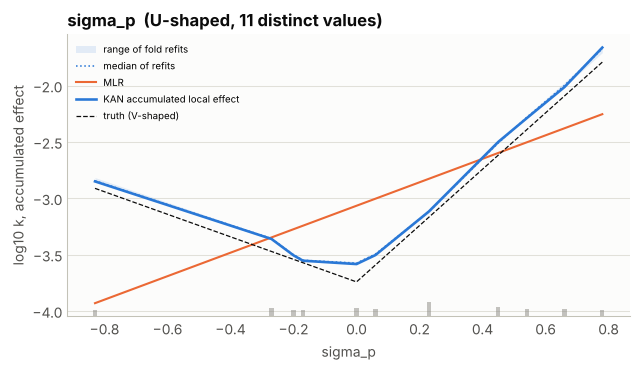

Held-out R2 on the mechanism-break target: KAN 0.982, MLR 0.481


KAN shape on sigma_p: U-shaped; refits: ['U-shaped', 'U-shaped', 'U-shaped', 'U-shaped', 'U-shaped']
RMSE to the truth at the observed sigma values: KAN 0.095, MLR 0.473


In [14]:
# Mechanism break: rho = -1.0 for sigma < 0 and +2.5 for sigma > 0, everything else unchanged.
def term_vshape(s):
    s = np.asarray(s, dtype=float)
    return np.where(s < 0, -1.0 * s, 2.5 * s)


y_break = (
    LOG_K0 + term_vshape(df.sigma_p)
    + sum(TRUTH[f](df[f].to_numpy()) for f in TRUTH if f != "sigma_p")
    + rng.normal(0, NOISE_SD, N)
)  # fmt: skip
kan_b = make_kan().fit(X_tr, y_break[idx_tr], maxiter=KAN_MAXITER)
lin_b = LinearRegression().fit(X_tr, y_break[idx_tr])
pe_b = accumulated_local_effects(
    kan_b, X, feature_names, ["sigma_p"], scaler=scaler, task=TASK, extra_models={"MLR": lin_b}
)
pe_b = accumulated_local_effects_cv(
    make_kan, X, y_break, feature_names, ["sigma_p"], task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=pe_b, verbose=False,
)["sigma_p"]  # fmt: skip
level_b = float(np.mean(kan_b.predict(scaler.transform(X))))
sig = X[:, feature_names.index("sigma_p")]
truth_b = term_vshape(pe_b.x_raw) - np.mean(term_vshape(sig)) + level_b

fig, ax = plt.subplots(figsize=(6.5, 3.8))
plot_partial_effect(ax, pe_b, ylabel=ALE_LABEL)
ax.plot(pe_b.x_raw, truth_b, color=INK, linewidth=1.2 * PX, linestyle="--", label="truth (V-shaped)", zorder=5)
ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()
r2_kan_b = r2_score(y_break[idx_te], kan_b.predict(X_te))
r2_lin_b = r2_score(y_break[idx_te], lin_b.predict(X_te))
print(f"Held-out R2 on the mechanism-break target: KAN {r2_kan_b:.3f}, MLR {r2_lin_b:.3f}")
fold_labels = [classify_shape(pe_b.x_std, c, scale=SHAPE_SCALE)[0] for c in pe_b.curves]
print(f"KAN shape on sigma_p: {pe_b.shape(scale=SHAPE_SCALE)[0]}; refits: {fold_labels}")
rmse_b = np.sqrt(np.mean((pe_b.y - truth_b) ** 2))
rmse_l = np.sqrt(np.mean((pe_b.extra["MLR"] - truth_b) ** 2))
print(f"RMSE to the truth at the observed sigma values: KAN {rmse_b:.3f}, MLR {rmse_l:.3f}")


### Reading

Every term the generator contains is recovered in all five refits, and the one term it does not
contain is caught because the refits cannot agree on its shape. This is the one dataset in the
series where the KAN is the best model: cross-validated R2 0.983 against 0.963 for gradient
boosting, better in 15 folds of 15. The difference from the real datasets is the design, not the
method: five independent descriptors, each with an effect of its own, and 600 reactions.

| Term in the generator | True shape | KAN shape (refits agreeing) | RMSE to truth, KAN | RMSE, linear |
|---|---|---|---|---|
| Hammett, rho = 1.5 | Linear | Linear (5 of 5) | 0.092 | 0.109 |
| Eyring, 15 kcal/mol | Monotone, concave | Linear (5 of 5) | 0.017 | 0.059 |
| Ligation cliff at 32 % | Step | Step (5 of 5) | 0.046 | 0.314 |
| Sabatier volcano, optimum -15 kcal/mol | Inverted U | Inverted U (5 of 5) | 0.028 | 0.729 |
| Unrelated descriptor | Constant | Complex (3 of 5) | 0.015 | 0.020 |

The noise in the data is 0.15 log units, and every curve is well inside it.

**The cliff lands where it was put.** The generator steps down at 32.0 %. The KAN curve's falling
edge is at 32.1 %, and at 31.95 to 32.12 % in the five refits. The class-balanced stump cuts at
32.6 %. A KAN given only the four real descriptors puts the edge at 31.8 % and scores R2 0.978.

**Both readings work here, and that is the point of the comparison.** These five descriptors are
independent by construction, so holding the others at their mean describes a compound that could
exist, and the partial effect and the accumulated local effect give the same shapes. The two
readings part ways only when descriptors are correlated, as in every real dataset in the series.

**The Eyring term reads as linear, and that is correct.** Over 288 to 368 K the exact curve bends
by less than the noise. A shape label is a claim about what the data can support.

**The unrelated descriptor is caught by its refits.** Its curve moves by 0.07 log units, two of the
refits call it Constant and three Complex. A shape the refits cannot agree on is not a finding.

**The mechanism break.** With a V-shaped Hammett relationship (rho = -1.0 below sigma = 0 and
+2.5 above), the KAN reaches R2 0.982 on held-out reactions against 0.481 for the linear model.
Its curve is U-shaped in all five refits and follows the truth to 0.095 against 0.473.


## 6. Summary dashboard

Four tiles, all from the numbers above: cross-validated score per model, the best single cuts,
the sensitivity grouped by reaction component, and the stability of the top response curves.


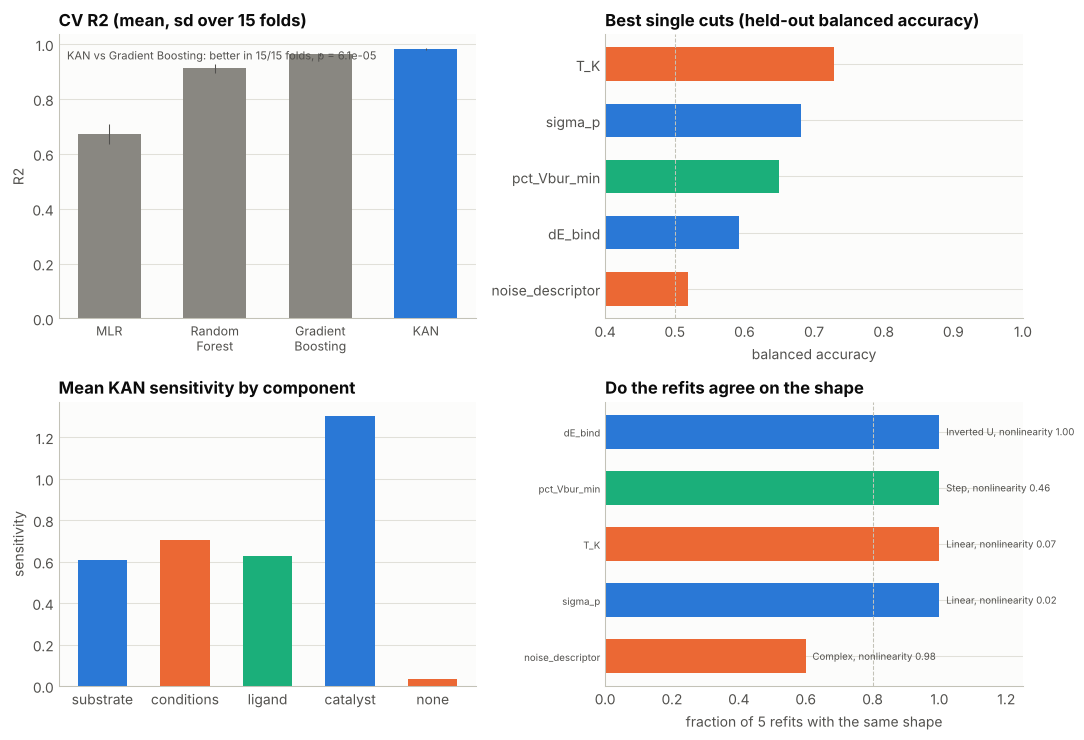

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
ax = axes[0, 0]
style_axes(ax)
s = cv_result.summary
names = list(s.index)
ax.bar(names, s[cv_result.metric + "_mean"], yerr=s[cv_result.metric + "_std"], color=[MUTED] * (len(names) - 1) + [SERIES[0]], width=0.6, linewidth=0, error_kw={"elinewidth": PX, "ecolor": INK_2})
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=9)
p = cv_result.pairwise
finish_axes(ax, f"CV {cv_result.metric.upper()} (mean, sd over {CV_SPLITS * CV_REPEATS} folds)", "", cv_result.metric.upper())
ax.text(0.02, 0.95, f"KAN vs {p['vs']}: better in {p['wins']}/{p['n']} folds, p = {p['p']:.2g}", transform=ax.transAxes, va="top", fontsize=8, color=INK_2)

ax = axes[0, 1]
style_axes(ax)
top5 = rules.head(5).iloc[::-1]
ax.barh(top5.Feature, top5.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top5.Feature], height=0.6, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
finish_axes(ax, "Best single cuts (held-out balanced accuracy)", "balanced accuracy", "")

ax = axes[1, 0]
style_axes(ax)
comp_sens = sens_df.groupby("Component")["Sensitivity"].mean().reindex(COMPONENTS)
ax.bar(comp_sens.index, comp_sens.values, color=[COMP_COLOR[c] for c in comp_sens.index], width=0.6, linewidth=0)
finish_axes(ax, "Mean KAN sensitivity by component", "", "sensitivity")

ax = axes[1, 1]
style_axes(ax)
st = stab.sort_values(["Fold agreement", "Nonlinearity"])
ax.barh(st.Feature, st["Fold agreement"], color=[COMP_COLOR[c] for c in st.Component], height=0.6, linewidth=0)
ax.axvline(0.8, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0, 1.25)
for yk, (a, nl, sh) in enumerate(zip(st["Fold agreement"], st["Nonlinearity"], st.Shape)):
    ax.text(a + 0.02, yk, f"{sh}, nonlinearity {nl:.2f}", va="center", fontsize=7, color=INK_2)
ax.tick_params(axis="y", labelsize=7)
finish_axes(ax, "Do the refits agree on the shape", "fraction of 5 refits with the same shape", "")
plt.tight_layout()
plt.show()
